# 3.5 Comparación de modelos y elección del finalista

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import config, utils, plotstyle
plotstyle.apply()
pd.options.display.float_format = "{:.4f}".format
ev = pd.read_csv(config.RESULTS_DIR / "evaluacion_resumen.csv", index_col=0)
finalist = (config.RESULTS_DIR / "finalista.txt").read_text().strip()
hist_var = utils.var_es(utils.portfolio_return(utils.train_window(utils.load_returns().values, 0)))[0]

## Tabla comparativa
Criterios del ranking (1 = mejor, gana la menor suma de rangos; desempate: pérdida cuantílica): desviación de excepciones, pérdida cuantílica, VaR medio y distancia KS al historial.

In [2]:
crit = ["desv_excepciones", "perdida_cuantilica", "VaR_medio", "KS_vs_historial"]
ranks = ev[crit].rank(method="min").astype(int).add_suffix(" (rango)")
pd.concat([ev[crit], ranks, ev[["suma_rangos"]]], axis=1).T

,GAN propia,Monte Carlo
desv_excepciones,2.0000,1.0000
perdida_cuantilica,0.0024,0.0027
VaR_medio,0.0180,0.0206
KS_vs_historial,0.0900,0.0760
desv_excepciones (rango),2.0000,1.0000
perdida_cuantilica (rango),1.0000,2.0000
VaR_medio (rango),1.0000,2.0000
KS_vs_historial (rango),2.0000,1.0000
suma_rangos,6.0000,6.0000


## Error de muestreo: ¿500 escenarios bastan para separar los modelos?

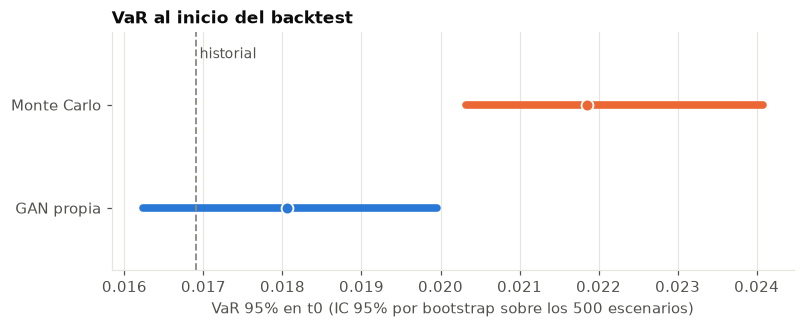

In [3]:
fig, ax = plt.subplots(figsize=(8, 2.8))
for i, (name, c) in enumerate([("GAN propia", plotstyle.C_GAN), ("Monte Carlo", plotstyle.C_MC)]):
    row = ev.loc[name]
    ax.hlines(i, row["VaR_t0_IC95_inf"], row["VaR_t0_IC95_sup"], color=c, lw=5, capstyle="round")
    ax.scatter(row["VaR_t0"], i, s=60, color=c, zorder=3, edgecolor="white", linewidth=1.2)
ax.axvline(hist_var, color=plotstyle.C_HIST, lw=1.2, ls="--"); ax.text(hist_var, 1.45, " historial", color=plotstyle.INK2, fontsize=9)
ax.set_yticks([0, 1], ["GAN propia", "Monte Carlo"]); ax.set_ylim(-0.6, 1.7); ax.grid(axis="y", visible=False)
ax.set_xlabel("VaR 95% en t0 (IC 95% por bootstrap sobre los 500 escenarios)"); ax.set_title("VaR al inicio del backtest")
plotstyle.save(fig, "04_ic_var"); plt.show()

## Robustez: la GAN depende de la semilla de entrenamiento
Se entrena la GAN 8 veces con semillas distintas (misma ventana, mismos 500 escenarios) para ver cuánto varía el VaR solo por azar del entrenamiento.

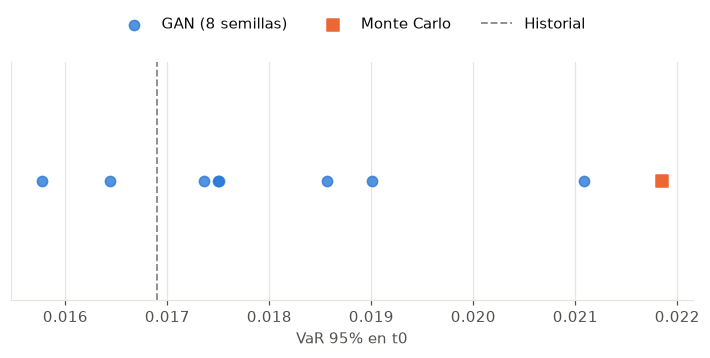

VaR GAN entre semillas: media=1.7905%  desv.=0.1652%  rango=[1.5771%, 2.1087%]


In [4]:
from multiprocessing import Pool
import robustez
seeds = list(range(100, 108))
with Pool(8) as pool:
    gan_vars = np.array(pool.map(robustez.var_gan_seed, seeds))
mc_var = ev.loc["Monte Carlo", "VaR_t0"]
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.scatter(gan_vars, np.zeros(len(gan_vars)), s=45, color=plotstyle.C_GAN, alpha=0.8, label="GAN (8 semillas)")
ax.scatter([mc_var], [0], s=70, marker="s", color=plotstyle.C_MC, label="Monte Carlo")
ax.axvline(hist_var, color=plotstyle.C_HIST, lw=1.2, ls="--", label="Historial")
ax.set_yticks([]); ax.grid(axis="y", visible=False); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.25))
ax.set_xlabel("VaR 95% en t0"); plotstyle.save(fig, "04_robustez_semillas"); plt.show()
print(f"VaR GAN entre semillas: media={gan_vars.mean():.4%}  desv.={gan_vars.std(ddof=1):.4%}  "
      f"rango=[{gan_vars.min():.4%}, {gan_vars.max():.4%}]")

In [5]:
print(f"Modelo finalista según el ranking: {finalist}")

Modelo finalista según el ranking: GAN propia


## Conclusión de la evaluación
- **El ranking empata (6 contra 6 puntos).** La GAN gana en pérdida cuantílica (0.0024 frente a 0.0027) y en VaR medio (1.80% frente a 2.06%); Monte Carlo gana en desviación de excepciones (2 frente a 3) y en distancia KS al historial. Según la regla declarada, el desempate por pérdida cuantílica elige a la **GAN**.
- **Esa elección es frágil**, por tres razones: (1) la diferencia de pérdida cuantílica está dominada por el día del -5.27%; (2) un VaR medio menor solo es una ventaja si la cobertura es adecuada, y la GAN tiene más excepciones (aunque Kupiec no las rechaza); (3) re-entrenar la GAN con otra semilla mueve el VaR en t0 entre 1.58% y 2.11% (desv. 0.17 pp), un rango comparable a la distancia entre ambos modelos.
- **Lectura honesta para el informe:** con 500 observaciones y 20 días de backtest, los datos no permiten afirmar que un método sea mejor. La GAN es competitiva en VaR, pero subestima las colas (ES y curtosis); Monte Carlo es más estable y conservador. Si el criterio prioritario fuera la fiabilidad del ES o la estabilidad, Monte Carlo sería la opción prudente.
- **Qué reforzaría la comparación:** un backtest más largo (p. ej. 250 días), varias semillas por día para promediar el ruido de entrenamiento y arquitecturas que modelen la volatilidad condicional (TimeGAN / GAN con convoluciones temporales).